1.What is GAN?

GAN stands for Generative Adversarial Network.
It is a Deep Learning architecture used to generate new data that look similar to the training data.

For example:
- Generate human faces.
- Generate handwritten digits.
- Generate cartoon images.
- Generate artificial product images.
- Generate realistic images.

input: Random Numbers

output: a generated

Training Data: (60000, 28, 28) (60000,)
Testing Data: (10000, 28, 28) (10000,)


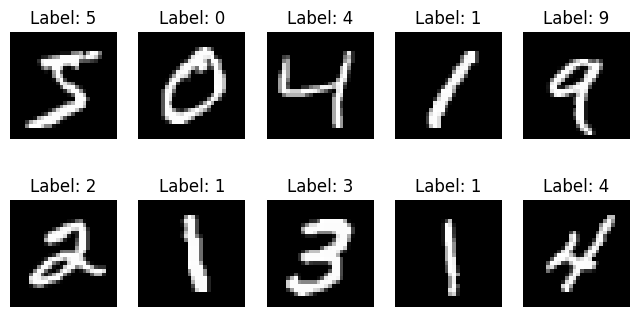

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers
# Explanation:
# - tensorflow: Deep learning framework.
# - numpy: Handles numerical operations
# - matplotlib: Displays images.
# - layers: Provides Dense, Conv2D, Flatten, etc.

# Step 3: Load the MNIST dataset
# MNIST contains 70,000 handwritten digit images
# - 60,000 training images.
# - 10,000 testing images.
# - Each image has dimensions 28 x 28.
# - Each image contains a digit between 0 and 9.

# Load MNIST dataset

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Check dataset shape
print("Training Data:", x_train.shape, y_train.shape)
print("Testing Data:", x_test.shape, y_test.shape)

# Display Some original images
plt.figure(figsize=(8,4))
for i in range(10):
  plt.subplot(2,5, i+1)
  plt.imshow(x_train[i], cmap='gray')
  plt.title(f"Label: {y_train[i]}")
  plt.axis('off')

plt.show()

#

In [ ]:
# Step 4: Preprocess the images.
# Our original pixel values range form 0 to 255.
# We need to normalize these values between -1 to +1.
# Why?
# Because our

In [ ]:
x_train = x_train.astype('float32')
# Normalize pixel values from 0 - 255 to -1 to +1
x_train = (x_train - 127.5)/127.5
# Add Channel dimension
x_train = np.expand_dims(x_train, axis=-1)
print(x_train.shape)

# Why do we add tje channel dimensions?
# >> Because CNN models expect image data in this format:
# (height, width, channels)

(60000, 28, 28, 1)


In [ ]:
# Step 5: Prepare the training dataset
BUFFER_SIZE = 60000
BATCH_SIZE = 256
train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(BUFFER_SIZE)
train_dataset = train_dataset.batch(BATCH_SIZE)
# Explanation:
# - Shuffle(): Randomly changes image order
# - batch(): Divides images into group of 256

In [ ]:
# Step 6: Create the Generator
# Now we will build our first neural network.
# The Generator takes 100 random numbers and generates a 28 × 28 image.
def build_generator():
    model = tf.keras.Sequential()
    # Input: 100 random numbers
    model.add(layers.Input(shape=(100,)))
    # Convert noise into 7*7*128 values
    model.add(layers.Dense(7 * 7 * 128))

    # Normalize values
    model.add(layers.BatchNormalization())

    # Apply activation
    model.add(layers.LeakyReLU())

    # Reshape into feature maps
    model.add(layers.Reshape((7, 7, 128)))

    # Increase image size from 7x7 to 14x14
    model.add(
        layers.Conv2DTranspose(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.BatchNormalization())

    model.add(layers.LeakyReLU())

    # Increase image size from 14x14 to 28x28
    model.add(
        layers.Conv2DTranspose(
            1,
            kernel_size=5,
            strides=2,
            padding="same",
            activation="tanh"
        )
    )

    return model

In [ ]:
# Let's understand the important layers.
# Layer	                          Purpose
# Dense	                          Converts random noise into feature values
# Batch                           Normalization	Stabilizes training
# Leaky                           ReLU	Adds non-linearity
# Reshape                       	Converts features into 7 × 7 feature maps
# Conv2D                          Transpose	Upsamples feature maps
# Tanh	                          Generates pixel values between -1 and +1

In [ ]:
# Create the Generator:
generator = build_generator()
generator.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 6272)           │       633,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │       204,864 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 865,281 (3.30 MB)

 Trainable params: 852,609 (3.25 MB)

 Non-trainable params: 12,672 (49.50 KB)

In [ ]:
# Generate 1 random noise vector
noise = tf.random.normal([1,100])
# Generate an image
generated_image = generator(noise, training=False)
print(generated_image.shape)
# Display the image
## plt.imshow(generated_image[0, :, :, 0], cmap='gray')

(1, 28, 28, 1)


In [ ]:
# Step 7: Create the Discriminator
# Now let's create the second neural network.
# The Discriminator receives an image and predicts whether it is real or fake.
def build_discriminator():

    model = tf.keras.Sequential()

    # Input image: 28x28 grayscale
    model.add(layers.Input(shape=(28, 28, 1)))

    # First convolution layer
    model.add(
        layers.Conv2D(
            64,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Second convolution layer
    model.add(
        layers.Conv2D(
            128,
            kernel_size=5,
            strides=2,
            padding="same"
        )
    )

    model.add(layers.LeakyReLU())

    model.add(layers.Dropout(0.3))

    # Convert feature maps into a vector
    model.add(layers.Flatten())

    # Final output
    model.add(layers.Dense(1))

    return model

In [ ]:
discriminator = build_discriminator()
discriminator.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Important: The final Dense layer has one output and no sigmoid activation. It produces a raw score called a logit.
# - Higher score: More likely to be real.
# - Lower score: More likely to be fake.
# We will use BinaryCrossentropy(from_logits=True) to calculate the loss.
# Step 8: Define loss functions
# Now comes the most important part of GAN training.
# We need two loss functions.
# 1. Generator Loss
# 2. Discriminator Loss

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy(
    from_logits=True
    )

In [ ]:
# Discriminator Loss:
# The Discriminator should identify real images as 1 and fake images as 0.
# def discriminator_loss(real_output, fake_output):

#     real_loss = cross_entropy(
#         tf.ones_like(real_output),
#         real_output
#     )

#     fake_loss = cross_entropy(
#         tf.zeros_like(fake_output),
#         fake_output
#     )

#     total_loss = real_loss + fake_loss

#     return total_loss

# Discriminator Loss (with one-sided label smoothing)
def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output) * 0.9, real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

In [ ]:
def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

In [ ]:
# Step 9: Define optimizers
# We use Adam
# Step 9: Define optimizers
# We use Adam optimizers to update the weights of both networks.
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

# Why two optimizers?
# Because the Generator and Discriminator have different trainable weights
# and are trained separately.

In [ ]:
# Step 10: Create
# Define noise dimension

noise_dim = 100


@tf.function
def train_step(real_images):

    # Number of images in current batch
    batch_size = tf.shape(real_images)[0]

    # Generate random noise
    noise = tf.random.normal([batch_size, noise_dim])

    # --------------------------------
    # Train Discriminator
    # --------------------------------

    with tf.GradientTape() as disc_tape:

        # Generate fake images
        generated_images = generator(noise, training=True)

        # Discriminator predictions on real images
        real_output = discriminator(
            real_images,
            training=True
        )

        # Discriminator predictions on fake images
        fake_output = discriminator(
            tf.stop_gradient(generated_images),
            training=True
        )

        # Calculate discriminator loss
        disc_loss = discriminator_loss(
            real_output,
            fake_output
        )

    # Calculate gradients
    disc_gradients = disc_tape.gradient(
        disc_loss,
        discriminator.trainable_variables
    )

    # Update discriminator weights
    discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            discriminator.trainable_variables
        )
    )

    # --------------------------------
    # Train Generator
    # --------------------------------

    noise = tf.random.normal([batch_size, noise_dim])

    with tf.GradientTape() as gen_tape:

        # Generate new fake images
        generated_images = generator(
            noise,
            training=True
        )

        # Ask discriminator to classify fake images
        fake_output = discriminator(
            generated_images,
            training=True
        )

        # Generator wants fake images to be classified as real
        gen_loss = generator_loss(fake_output)

    # Calculate generator gradients
    gen_gradients = gen_tape.gradient(
        gen_loss,
        generator.trainable_variables
    )

    # Update generator weights
    generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            generator.trainable_variables
        )
    )

    return gen_loss, disc_loss

Epoch 1/60 | G: 0.9425 | D: 1.1747
Epoch 2/60 | G: 0.8923 | D: 1.3314
Epoch 3/60 | G: 0.8898 | D: 1.3323
Epoch 4/60 | G: 0.9161 | D: 1.3007
Epoch 5/60 | G: 0.9836 | D: 1.2563
Epoch 6/60 | G: 1.0300 | D: 1.2169
Epoch 7/60 | G: 1.0189 | D: 1.2293
Epoch 8/60 | G: 1.0172 | D: 1.2718
Epoch 9/60 | G: 0.9894 | D: 1.2778
Epoch 10/60 | G: 0.9673 | D: 1.2824


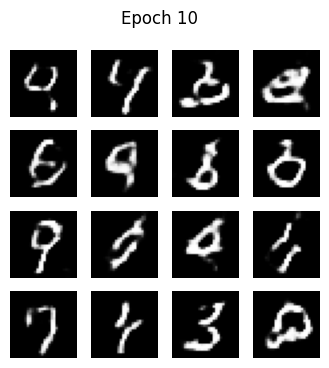

Epoch 11/60 | G: 0.9694 | D: 1.2891
Epoch 12/60 | G: 0.9690 | D: 1.2897
Epoch 13/60 | G: 0.9565 | D: 1.2913
Epoch 14/60 | G: 0.9614 | D: 1.2899
Epoch 15/60 | G: 0.9572 | D: 1.2898
Epoch 16/60 | G: 0.9551 | D: 1.2890
Epoch 17/60 | G: 0.9638 | D: 1.2916
Epoch 18/60 | G: 0.9580 | D: 1.2859
Epoch 19/60 | G: 0.9621 | D: 1.2826
Epoch 20/60 | G: 0.9656 | D: 1.2851


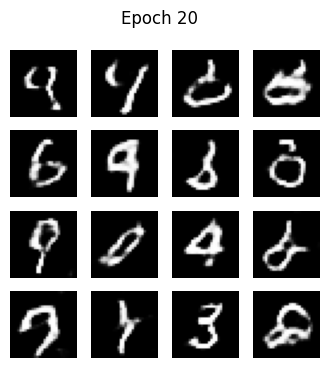

Epoch 21/60 | G: 0.9744 | D: 1.2833
Epoch 22/60 | G: 0.9682 | D: 1.2810
Epoch 23/60 | G: 0.9799 | D: 1.2802
Epoch 24/60 | G: 0.9786 | D: 1.2798
Epoch 25/60 | G: 0.9854 | D: 1.2771
Epoch 26/60 | G: 0.9779 | D: 1.2753
Epoch 27/60 | G: 0.9801 | D: 1.2763
Epoch 28/60 | G: 0.9921 | D: 1.2782
Epoch 29/60 | G: 0.9869 | D: 1.2719
Epoch 30/60 | G: 0.9884 | D: 1.2746


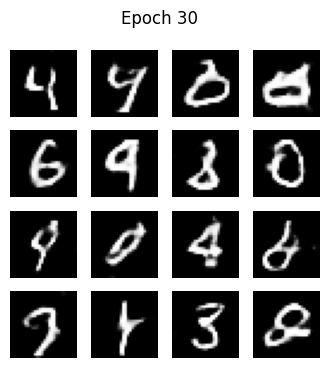

Epoch 31/60 | G: 1.0007 | D: 1.2743
Epoch 32/60 | G: 0.9900 | D: 1.2719
Epoch 33/60 | G: 0.9899 | D: 1.2714
Epoch 34/60 | G: 0.9906 | D: 1.2718
Epoch 35/60 | G: 0.9936 | D: 1.2693
Epoch 36/60 | G: 1.0010 | D: 1.2723
Epoch 37/60 | G: 0.9977 | D: 1.2699
Epoch 38/60 | G: 0.9935 | D: 1.2691
Epoch 39/60 | G: 0.9929 | D: 1.2697
Epoch 40/60 | G: 1.0022 | D: 1.2691


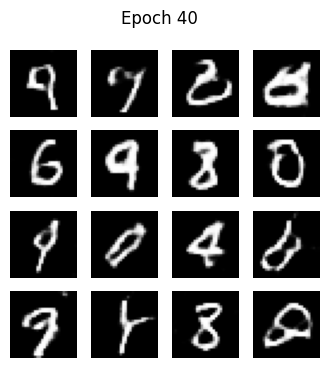

Epoch 41/60 | G: 0.9918 | D: 1.2690
Epoch 42/60 | G: 0.9982 | D: 1.2735
Epoch 43/60 | G: 0.9952 | D: 1.2705
Epoch 44/60 | G: 1.0024 | D: 1.2695
Epoch 45/60 | G: 1.0035 | D: 1.2714
Epoch 46/60 | G: 1.0008 | D: 1.2726
Epoch 47/60 | G: 0.9978 | D: 1.2709
Epoch 48/60 | G: 1.0061 | D: 1.2706
Epoch 49/60 | G: 1.0047 | D: 1.2694
Epoch 50/60 | G: 0.9948 | D: 1.2693


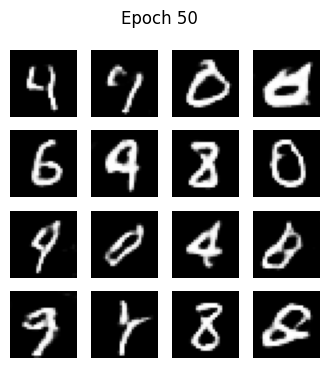

Epoch 51/60 | G: 1.0012 | D: 1.2714
Epoch 52/60 | G: 1.0021 | D: 1.2694
Epoch 53/60 | G: 0.9988 | D: 1.2689
Epoch 54/60 | G: 1.0120 | D: 1.2741
Epoch 55/60 | G: 0.9995 | D: 1.2711
Epoch 56/60 | G: 1.0104 | D: 1.2673
Epoch 57/60 | G: 1.0011 | D: 1.2680
Epoch 58/60 | G: 1.0000 | D: 1.2684
Epoch 59/60 | G: 1.0113 | D: 1.2702
Epoch 60/60 | G: 1.0142 | D: 1.2684


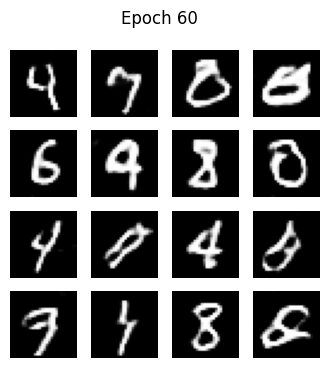

In [ ]:
# Step 11: Train the GAN model
# Now we will train both networks.
# EPOCHS = 30

# for epoch in range(EPOCHS):

#     gen_loss_total = 0
#     disc_loss_total = 0
#     batches = 0

#     for image_batch in train_dataset:

#         gen_loss, disc_loss = train_step(image_batch)

#         gen_loss_total += gen_loss
#         disc_loss_total += disc_loss

#         batches += 1

#     print(
#         f"Epoch {epoch + 1}/{EPOCHS} | "
#         f"Generator Loss: {gen_loss_total / batches:.4f} | "
#         f"Discriminator Loss: {disc_loss_total / batches:.4f}"
#     )

# Fixed noise so you can compare progress across epochs
seed = tf.random.normal([16, noise_dim])

def show_images(epoch):
    preds = generator(seed, training=False)
    plt.figure(figsize=(4, 4))
    for i in range(16):
        plt.subplot(4, 4, i + 1)
        plt.imshow((preds[i, :, :, 0] + 1) / 2, cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Epoch {epoch}")
    plt.show()

EPOCHS = 60
g_hist, d_hist = [], []

for epoch in range(EPOCHS):
    g_tot = d_tot = 0.0
    n = 0
    for batch in train_dataset:
        g, d = train_step(batch)
        g_tot += g
        d_tot += d
        n += 1
    g_hist.append(float(g_tot / n))
    d_hist.append(float(d_tot / n))
    print(f"Epoch {epoch+1}/{EPOCHS} | G: {g_hist[-1]:.4f} | D: {d_hist[-1]:.4f}")
    if (epoch + 1) % 10 == 0:
        show_images(epoch + 1)

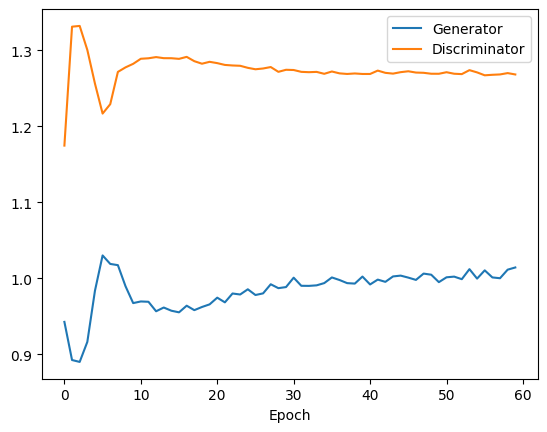

In [ ]:
plt.plot(g_hist, label="Generator")
plt.plot(d_hist, label="Discriminator")
plt.legend()
plt.xlabel("Epoch")
plt.show()

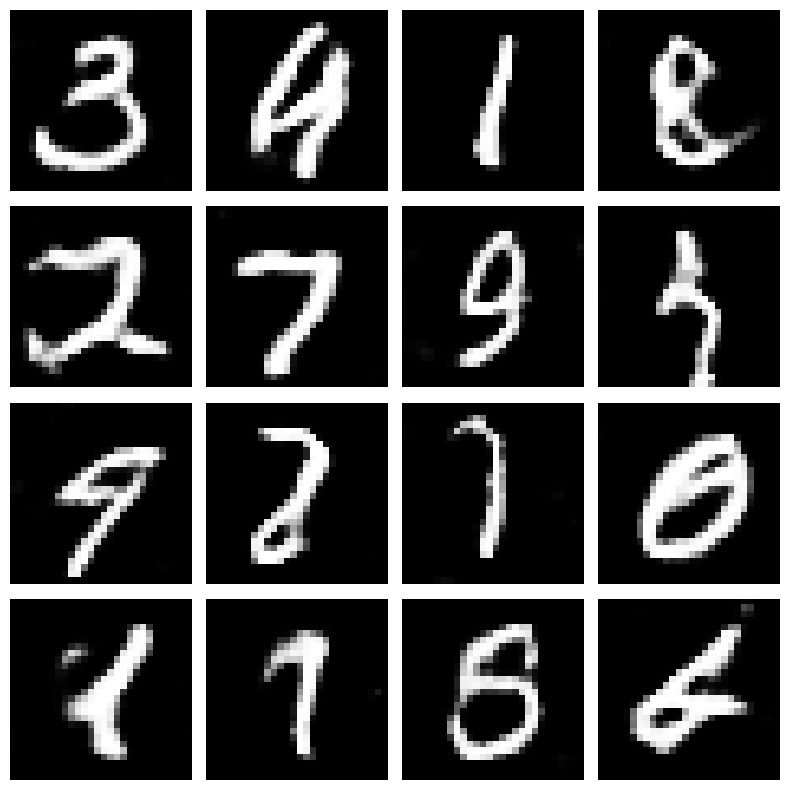

In [ ]:
# Step 12: Generate new images
# Final output
# Now our Generator has learned from the MNIST dataset.
# Let's generate 16 new images.
# Generate 16 random noise vectors

noise = tf.random.normal([16, noise_dim])

# Generate images

predictions = generator(noise, training=False)

# Display generated images

plt.figure(figsize=(8, 8))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    # Convert pixel values from -1 to +1 into 0 to 1
    image = (predictions[i, :, :, 0] + 1) / 2

    plt.imshow(image, cmap="gray")

    plt.axis("off")

plt.tight_layout()

plt.show()